# The PPMI data

The Parkinson's Progression Markers Initiative (PPMI) follows people with early Parkinson's disease, people at risk and healthy controls, with clinical, cognitive, imaging and biospecimen assessments at regular visits. Researchers [apply for access](https://www.ppmi-info.org/access-data-specimens/download-data), sign the data use agreement, and then download the data from the LONI Image and Data Archive (IDA).

The agreement does not allow participant-level data to be shared, so this repository holds analysis code and reviewed aggregate outputs. Download the data with your own IDA account as described below. Preserve aggregate tables and static plots when committing; keep raw data, participant identifiers and individual results out of version control. The agreement also forbids putting individual-level PPMI data into AI tools. GitHub displays the saved outputs without running the notebook, so rerun locally, review and save before publishing refreshed results.

`code/data.py` loads the downloads into an in-memory DuckDB database each time `data.PPMI()` runs, so a fresh download is picked up straight away. Run the notebooks from the `notebooks` folder after `pip install duckdb jupyterlab matplotlib numpy pandas`.

## Downloading

Put the downloads in this layout. Set `PPMI_DATA` to keep them somewhere other than `~/ppmi`.

```
~/ppmi
├── study/      Study Data CSVs, named as IDA names them
└── imaging/    image-search CSVs, any names
```

**Study data.** In IDA choose *Download → Study Data*, download the tables below and save them in `study/` without renaming them. IDA adds the download date to each name, for example `Participant_Status_13Nov2026.csv`. If a table has been downloaded more than once, `data.py` uses the newest copy.

| IDA group | Tables |
|---|---|
| Subject Characteristics | Participant Status, Demographics, Socio-Economics, Age at visit |
| Motor Assessments | MDS-UPDRS Part III |
| Non-motor Assessments | Hopkins Verbal Learning Test - Revised, Benton Judgement of Line Orientation, Letter - Number Sequencing, Modified Semantic Fluency, Symbol Digit Modalities Test |
| Imaging | Xing Core Lab - Quant SBR, Grey Matter Volume, and optionally FS7 ASEG VOL and FS7 APARC CTH |

**Image searches.** In IDA choose *Search → Advanced Search*. Tick Research Group *PD* and the visits *Screening*, *Baseline*, *Month 12*, *Month 24*, *Month 36*, *Month 48* and *Month 60*. Run one search per modality, with Subject ID, Visit and Modality shown in the results (the CSV keeps only the columns the results show), and download each result as CSV into `imaging/`:

- SPECT (DaTscan): Modality *SPECT*.
- T1-weighted MRI: Modality *MRI*, Weighting *T1*, Acquisition Type *3D*.
- Diffusion MRI: Modality *DTI*.

The image searches only feed the first section of `audit.ipynb`. Without them that section is empty and everything else still runs.

In [1]:
%reload_ext autoreload
%autoreload 2
%matplotlib inline
import sys
sys.path.append("../code")

import numpy as np
import pandas as pd

import data
import plot

p = data.PPMI()

pd.Series(p.files, name="file").sort_index()

/Users/ovd/research/ImpactScholars/notebooks/../code/data.py:70: UserWarning: Skipped idaSearch_11_10_2026 (1).csv: it has no Visit or Modality column. Show these columns in the IDA search results and download it again.
  warnings.warn(f"Skipped {path.name}: it has no {' or '.join(missing)} column. Show these columns in the IDA search results and download it again.")
/Users/ovd/research/ImpactScholars/notebooks/../code/data.py:70: UserWarning: Skipped idaSearch_11_10_2026.csv: it has no Visit or Modality column. Show these columns in the IDA search results and download it again.
  warnings.warn(f"Skipped {path.name}: it has no {' or '.join(missing)} column. Show these columns in the IDA search results and download it again.")


age_at_visit                                                   Age_at_visit_10Nov2026.csv
benton_judgement_of_line_orientation    Benton_Judgement_of_Line_Orientation_10Nov2026...
demographics                                                   Demographics_10Nov2026.csv
fs7_aseg_vol                                                   FS7_ASEG_VOL_10Nov2026.csv
grey_matter_volume                                       Grey_Matter_Volume_10Nov2026.csv
hopkins_verbal_learning_test_revised    Hopkins_Verbal_Learning_Test_-_Revised_10Nov20...
letter_number_sequencing                         Letter_-_Number_Sequencing_10Nov2026.csv
mds_updrs_part_iii                                       MDS-UPDRS_Part_III_10Nov2026.csv
modified_semantic_fluency                         Modified_Semantic_Fluency_10Nov2026.csv
participant_status                                       Participant_Status_10Nov2026.csv
socio_economics                                             Socio-Economics_10Nov2026.csv
symbol_dig

## Participants and visits

Every table names the participant in `PATNO` and the visit in `EVENT_ID`. The visits used here are SC (screening), BL (baseline), and V04, V06, V08, V10 and V12 at months 12, 24, 36, 48 and 60. Dates are recorded to the month as MM/YYYY, and the `ppmi_date` macro in `data.py` turns them into dates. This table counts the participants each table has at each of those visits.

In [2]:
visits = ["SC", "BL", "V04", "V06", "V08", "V10", "V12"]
coverage = {
    name: p.sql(f'SELECT EVENT_ID, count(DISTINCT PATNO) AS participants FROM "{name}" GROUP BY ALL').set_index("EVENT_ID").participants
    for name in p.files
    if "EVENT_ID" in p.db.table(name).columns
}
pd.DataFrame(coverage).T.reindex(columns=visits).fillna(0).astype(int)

EVENT_ID,SC,BL,V04,V06,V08,V10,V12
modified_semantic_fluency,0,5326,3836,3100,2146,1376,1016
mds_updrs_part_iii,1167,5344,3858,3161,2234,1444,1071
age_at_visit,8853,5438,4072,3377,2361,1531,1141
fs7_aseg_vol,0,1713,0,0,0,0,0
symbol_digit_modalities_test,0,5318,3823,3093,2140,1370,1013
hopkins_verbal_learning_test_revised,0,5325,3832,3097,2148,1374,1013
demographics,7639,0,0,0,0,0,0
letter_number_sequencing,0,5319,3827,3086,2140,1368,1011
grey_matter_volume,0,132,0,126,0,105,0
benton_judgement_of_line_orientation,0,5320,3826,3088,2142,1373,1011


## Cohorts

`Participant_Status` assigns each person to a cohort (`COHORT` 1 is Parkinson's disease and 2 is healthy controls) and records their place in the study (`ENROLL_STATUS`). The PPMI data user guide suggests keeping participants who are enrolled, withdrew or completed. Screen failures and exclusions have no visit data.

In [3]:
p.sql("""
    SELECT COHORT, COHORT_DEFINITION, lower(ENROLL_STATUS) AS status, count(*) AS participants
    FROM participant_status GROUP BY ALL
""").pivot_table(index=["COHORT", "COHORT_DEFINITION"], columns="status", values="participants", aggfunc="sum", fill_value=0)

,status,baseline,baseline withdraw,complete,declined,enrolled,excluded,lost to follow-up,pending,screen failed,screen scheduled,screened,withdraw deceased,withdrew
COHORT,COHORT_DEFINITION,,,,,,,,,,,,,
1,Parkinson's Disease,8,22,34,47,1318,76,0,6,387,0,0,61,312
2,Healthy Control,0,1,11,14,222,35,0,0,55,0,0,7,95
3,SWEDD,0,0,50,14,1,3,0,0,0,0,0,0,13
4,Prodromal,28,31,6,41,2832,157,1,180,2978,11,184,25,211


## The six cognitive tests

The PPMI Cognitive Summary Score (CSS) combines six tests from five tables: HVLT-R immediate and delayed recall, Benton Judgement of Line Orientation (JLO), Letter-Number Sequencing (LNS), semantic (animal) fluency and the Symbol Digit Modalities Test (SDMT). `data.py` stacks them into one view, `cognition`, with a row per participant, visit and test. HVLT-R immediate recall is the sum of the three learning trials, so it is missing unless all three are recorded.

In [4]:
p.sql("""
    SELECT test, EVENT_ID, count(DISTINCT PATNO) AS participants
    FROM cognition WHERE score IS NOT NULL GROUP BY ALL
""").pivot(index="test", columns="EVENT_ID", values="participants").reindex(columns=visits)

EVENT_ID,SC,BL,V04,V06,V08,V10,V12
test,,,,,,,
hvlt_delayed,NaN,5318,3827,3093,2145,1367,1008
hvlt_immediate,NaN,5324,3831,3097,2148,1372,1012
jlo,NaN,5316,3825,3088,2139,1368,1010
lns,NaN,5319,3827,3086,2140,1368,1011
sdmt,NaN,5316,3823,3093,2138,1369,1013
semantic,NaN,5326,3836,3100,2146,1375,1016


## DaTscan and grey-matter volume

`Xing_Core_Lab_-_Quant_SBR` holds DaTscan specific binding ratios for the left and right caudate and putamen, with cerebral white matter as the reference region (`*_REF_CWM`), for scans marked as analysed (`DATSCAN_ANALYZED`). `Grey_Matter_Volume` has one total grey-matter volume per MRI (`GM_VOLUME`) and the scan month (`MRIDATE`).

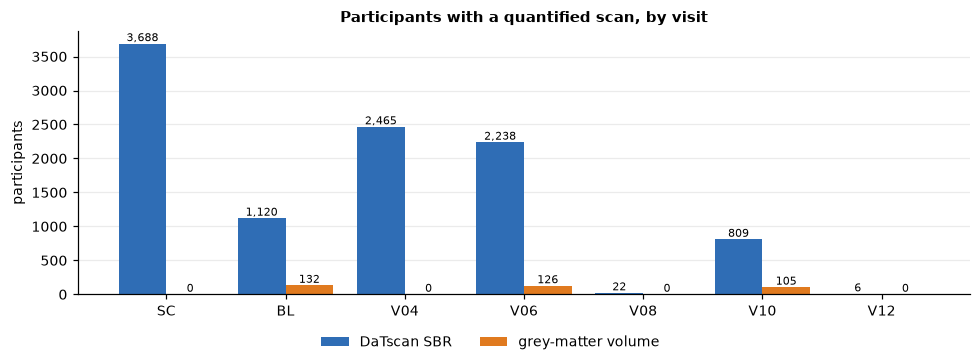

In [5]:
scans = p.sql("""
    SELECT EVENT_ID, 'DaTscan SBR' AS measure, count(DISTINCT PATNO) AS participants
    FROM xing_core_lab_quant_sbr WHERE upper(DATSCAN_ANALYZED) = 'YES' GROUP BY ALL
    UNION ALL
    SELECT EVENT_ID, 'grey-matter volume', count(DISTINCT PATNO)
    FROM grey_matter_volume WHERE num(GM_VOLUME) > 0 GROUP BY ALL
""")
plot.grouped(scans.pivot(index="EVENT_ID", columns="measure", values="participants").reindex(visits), "Participants with a quantified scan, by visit")

## Image searches

An image search lists every image series with the participant (`Subject ID` in IDA, the same number as `PATNO`), the visit name and the modality. `data.py` stacks all searches into one table, `images`, and maps visit names such as *Month 12* to codes such as V04.

In [6]:
p.sql("SELECT modality, visit, event, count(*) AS series, count(DISTINCT PATNO) AS participants FROM images GROUP BY ALL ORDER BY ALL")

,modality,visit,event,series,participants
